# KF 합성 실험 — 방위열에서 각속도 뽑기 (Step8c)

> 2026-10-26 실험, 2026-10-27 노트북 · 계산 도구 [`track/kf.py`](../track/kf.py), [`track/sim_kf.py`](../track/sim_kf.py) · 커널: `Tools/.venv`
> 결론은 마지막 절에 **결론 후보**로만 적는다. 사용자가 확인한 뒤 결정(T2)으로 올린다.

**질문:** doa.c는 0.246 s마다 방위 하나를 낸다. 여기서 **각속도**(초당 몇 도 도나)를 뽑아 "제자리 음원 vs 움직이는 음원"을 가를 수 있나? KF의 과정 잡음 σa 하나로 두 경우를 다 만족할 수 있나?

**Step8c 통과 기준 (제안, 사용자 확인 전):** 고정 음원에서 |ω| ≤ 3°/s인 시간 ≥ 95%.

**장면 (sim_kf.py와 같음)** — 측정 = 정답 + 3° 흔들림, 10%는 측정 없음(무효), 3%는 엉뚱한 방위(반사·다른 음원 흉내)

| 장면 | 정답 |
|---|---|
| A 고정 음원 | 60°에 고정 (세탁기·엔진 역할) |
| B 일정 회전 | 30°/s |
| C 직선 통과 | 15 m/s, 최근접 10 m → 최근접에서 약 86°/s |
| D 측정 끊김 | B와 같고 12 ~ 15 s 동안 측정 없음 |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import matplotlib.pyplot as plt
import track.kf as kf
import track.sim_kf as sim
plt.rcParams["font.family"] = "Malgun Gothic"; plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 90; plt.rcParams["mathtext.fontset"] = "dejavusans"
NOISE = 3.0
t, S = sim.scenes()
def measure_all(seed):
    # sim_kf.py와 같은 순서로 장면마다 측정을 만든다 (seed 1 = 2026-10-26 보고와 같은 데이터)
    rng = np.random.default_rng(seed)
    return {n: sim.measure(tr, t, rng, NOISE, gap=(12, 15) if n.startswith("D") else None) for n, tr in S.items()}
Z = measure_all(1)
print(f"주기 DT = 3072 / 12500 = {kf.DT:.3f} s, 장면 길이 {t[-1]:.1f} s, 방위 {len(t)}개")

주기 DT = 3072 / 12500 = 0.246 s, 장면 길이 30.0 s, 방위 123개


## 1. 측정된 방위열

KF에 들어가는 것은 이 점들뿐이다. 회색 점 = 측정 (빈칸 = 무효, 멀리 튄 점 = 엉뚱한 방위), 검은 선 = 정답.

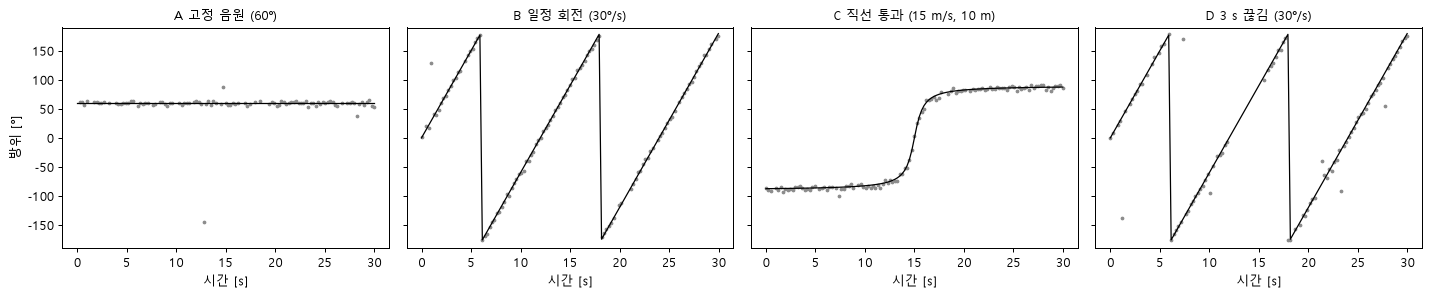

In [2]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for a, (n, tr) in zip(ax, S.items()):
    a.plot(t, Z[n], ".", ms=4, color="0.55"); a.plot(t, tr, "k", lw=1)
    a.set_title(n, fontsize=10); a.set_xlabel("시간 [s]"); a.set_ylim(-190, 190)
ax[0].set_ylabel("방위 [°]"); plt.tight_layout(); plt.show()

## 2. 그냥 빼서 나누면? — 차분 각속도

가장 쉬운 방법은 (이번 방위 − 지난 방위) ÷ 0.246 s 다.

- 방위 하나가 ±3° 흔들리면 3 ÷ 0.246 = **12.2°/s**.
- 두 값이 모두 흔들리므로 √2배 → 약 **17°/s** 흔들림.
- 고정 음원 기준이 ±3°/s인데, 흔들림만 17°/s라 판정이 안 된다.

예상 17.3°/s, 측정 표준편차 25.6°/s (엉뚱한 방위 3%가 섞여 예상보다 조금 큼), |ω| ≤ 3°/s 비율 14%


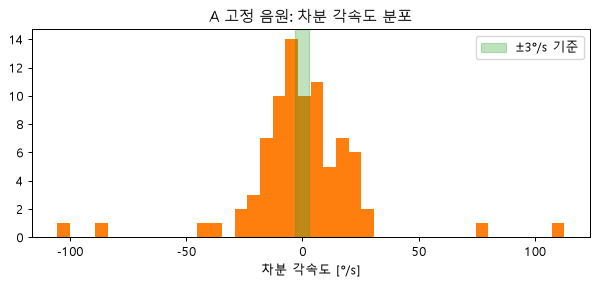

In [3]:
z = Z["A 고정 음원 (60°)"]
w = np.diff(z) / kf.DT
w = w[np.isfinite(w) & (np.abs(w) < 200)]
print(f"예상 {np.sqrt(2) * NOISE / kf.DT:.1f}°/s, 측정 표준편차 {np.std(w):.1f}°/s (엉뚱한 방위 3%가 섞여 예상보다 조금 큼), |ω| ≤ 3°/s 비율 {np.mean(np.abs(w) <= 3) * 100:.0f}%")
plt.figure(figsize=(8, 3)); plt.hist(w, bins=40, color="C1"); plt.axvspan(-3, 3, color="C2", alpha=.3, label="±3°/s 기준")
plt.xlabel("차분 각속도 [°/s]"); plt.title("A 고정 음원: 차분 각속도 분포"); plt.legend(); plt.show()

## 3. KF 한 주기를 손으로 따라가기

상태 x = [θ 방위, ω 각속도], 불확실성 P (2×2). 매 주기 두 단계:

1. **예측** — "지난 각속도로 0.246 s 돌았다면": θ ← θ + ω·DT. P는 Q만큼 커진다.
2. **갱신** — 측정 z와 예측의 차이 y = z − θ. 그 차이를 이득 K만큼 반영한다.
   K[0] = 방위를 측정 쪽으로 당기는 정도, K[1] = 그 차이로 각속도를 고치는 정도.

장면 C(통과), σa = 30의 처음 6주기.

In [4]:
f = kf.AngleKF(sigma_a=30)
z = Z["C 직선 통과 (15 m/s, 10 m)"]
print(" 주기 |  측정 z | 예측 θ   예측 ω | 차이 y |  K[0]   K[1]  | 갱신 θ   갱신 ω | sd θ  sd ω | 상태")
for k in range(6):
    zk = None if np.isnan(z[k]) else float(z[k])
    if f.x is not None:
        f2 = kf.AngleKF(sigma_a=30); f2.x, f2.P, f2.t = f.x.copy(), f.P.copy(), f.t
        f2.predict(t[k]); th_p, om_p = f2.x
        S_ = f2.P[0, 0] + f2.R; K = f2.P[:, 0] / S_; y = kf.wrap(zk - th_p) if zk is not None else np.nan
    else:
        th_p = om_p = y = np.nan; K = [np.nan, np.nan]
    o = f.step(t[k], zk)
    print(f"{k:4d} | {z[k]:7.1f} | {th_p:7.1f} {om_p:7.1f} | {y:6.1f} | {K[0]:.3f} {K[1]:6.3f} | "
          f"{o.get('theta', np.nan):7.1f} {o.get('omega', np.nan):7.1f} | {o.get('sd_theta', np.nan):4.1f} {o.get('sd_omega', np.nan):5.1f} | {o['status']}")

 주기 |  측정 z | 예측 θ   예측 ω | 차이 y |  K[0]   K[1]  | 갱신 θ   갱신 ω | sd θ  sd ω | 상태
   0 |   -86.6 |     nan     nan |    nan | nan    nan |   -86.6     0.0 |  3.0  90.0 | start
   1 |   -89.1 |   -86.6     0.0 |   -2.5 | 0.982  3.931 |   -89.1    -9.9 |  3.0  17.4 | update
   2 |   -90.8 |   -91.5    -9.9 |    0.7 | 0.834  2.142 |   -90.9    -8.4 |  2.7  10.4 | update
   3 |     nan |   -93.0    -8.4 |    nan | 0.730  1.572 |   -93.0    -8.4 |  4.9  12.7 | coast
   4 |   -86.5 |   -95.1    -8.4 |    8.6 | 0.871  1.419 |   -87.6     3.8 |  2.8   8.7 | update
   5 |   -90.5 |   -86.6     3.8 |   -3.9 | 0.684  1.336 |   -89.3    -1.4 |  2.5   8.9 | update


**읽는 법:** 처음엔 각속도를 모르니(sd ω가 큼) K[1]이 커서, 방위 차이가 생길 때마다 각속도를 크게 고친다. 주기가 지날수록 sd가 줄고 K가 작아진다.

## 4. σa — "각속도가 한 주기에 얼마나 바뀔 수 있다고 보나"

Q = σa² · [[DT⁴/4, DT³/2], [DT³/2, DT²]] (이산 백색 가속도 모델). 뜻은 한 줄이다: **매 주기 각속도가 약 σa × DT만큼 무작위로 바뀔 수 있다.**

- σa 크다 → 각속도가 잘 바뀐다고 봄 → 급한 움직임을 잘 따라가지만, 측정 흔들림도 움직임으로 믿는다.
- σa 작다 → 각속도가 거의 안 바뀐다고 봄 → 고정 음원에서 ω가 0에 붙지만, 급히 도는 음원을 놓친다.

In [5]:
for sa in (5, 30, 100):
    print(f"σa = {sa:3d} °/s² → 한 주기 각속도 변화 약 {sa * kf.DT:5.1f} °/s,  Q =", np.round(kf.AngleKF(sigma_a=sa)._Q(kf.DT), 3).tolist())

σa =   5 °/s² → 한 주기 각속도 변화 약   1.2 °/s,  Q = [[0.023, 0.186], [0.186, 1.51]]
σa =  30 °/s² → 한 주기 각속도 변화 약   7.4 °/s,  Q = [[0.821, 6.68], [6.68, 54.358]]
σa = 100 °/s² → 한 주기 각속도 변화 약  24.6 °/s,  Q = [[9.12, 74.217], [74.217, 603.98]]


## 5. σa 세 값으로 전 장면 추적

> ▶ **예측 지점 (T1)**: 처음 보는 경우, 실행 전에 "σa = 5에서 A와 C가 각각 어떻게 될까"를 대화에서 먼저 예측한다.

파란 선 = KF 방위, 주황 선 = KF 각속도, 검은 선 = 정답.

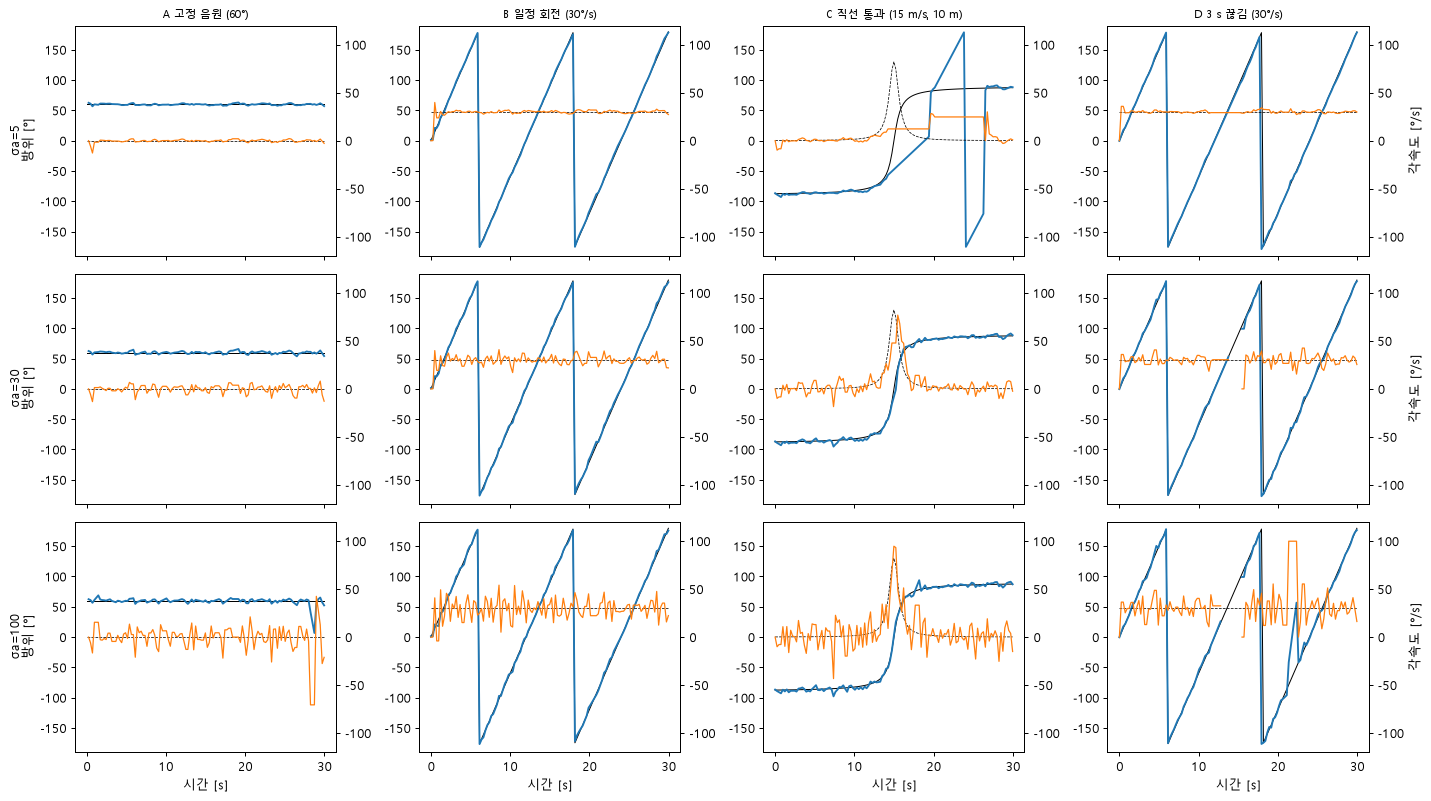

In [6]:
SAS = (5, 30, 100)
fig, ax = plt.subplots(len(SAS), 4, figsize=(16, 9), sharex=True)
R = {}
for r_, sa in enumerate(SAS):
    for c_, (n, tr) in enumerate(S.items()):
        out = kf.track(t, Z[n], sigma_a=sa); R[(sa, n)] = out
        th = np.array([o.get("theta", np.nan) for o in out]); om = np.array([o.get("omega", np.nan) for o in out])
        a = ax[r_, c_]; a2 = a.twinx()
        a.plot(t, tr, "k", lw=.8); a.plot(t, th, color="C0", lw=1.5); a.set_ylim(-190, 190)
        a2.plot(t, sim.true_omega(tr, t), "k--", lw=.6); a2.plot(t, om, color="C1", lw=1); a2.set_ylim(-120, 120)
        if r_ == 0: a.set_title(n, fontsize=9)
        if c_ == 0: a.set_ylabel(f"σa={sa}\n방위 [°]")
        if c_ == 3: a2.set_ylabel("각속도 [°/s]")
for a in ax[-1]: a.set_xlabel("시간 [s]")
plt.tight_layout(); plt.show()

## 6. 지표

- **A 고정 음원**: 수렴 구간(처음 3 s)을 뺀 뒤 |ω| ≤ 3°/s 비율 (기준 ≥ 95%)
- **C 통과**: 방위 오차 p95, 관문에서 버린 측정 수, 추적을 놓친 횟수

In [7]:
rows = []
print("σa  | A: |ω|≤3 비율 | C: 방위 오차 p95 | C: 버림 | C: 놓침 | D: 놓침")
for sa in SAS:
    oa = R[(sa, "A 고정 음원 (60°)")]; om = np.array([o.get("omega", np.nan) for o in oa])
    ok = (t > 3) & np.isfinite(om); still = np.mean(np.abs(om[ok]) <= 3) * 100
    oc = R[(sa, "C 직선 통과 (15 m/s, 10 m)")]; trc = S["C 직선 통과 (15 m/s, 10 m)"]
    th = np.array([o.get("theta", np.nan) for o in oc]); m = np.isfinite(th)
    p95 = np.percentile(np.abs(kf.wrap(th[m] - trc[m])), 95)
    st = [o["status"] for o in oc]; sd = [o["status"] for o in R[(sa, "D 3 s 끊김 (30°/s)")]]
    rows.append(dict(sa=sa, still=still, p95=p95))
    print(f"{sa:3d} | {still:12.0f}% | {p95:14.1f}° | {st.count('reject'):6d} | {st.count('lost'):6d} | {sd.count('lost'):6d}")

σa  | A: |ω|≤3 비율 | C: 방위 오차 p95 | C: 버림 | C: 놓침 | D: 놓침
  5 |          100% |          116.3° |     44 |      1 |      0
 30 |           49% |            5.2° |      2 |      0 |      1
100 |           24% |            6.2° |      0 |      0 |      2


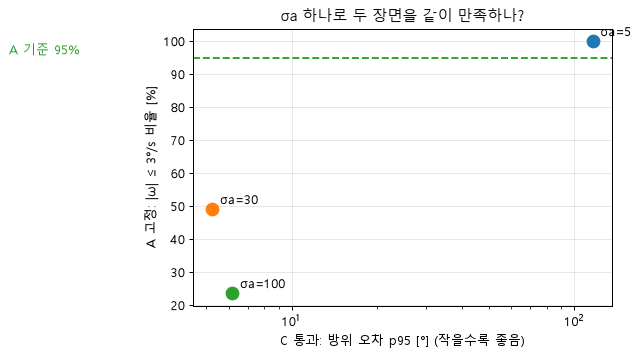

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
for r in rows:
    ax.plot(r["p95"], r["still"], "o", ms=10); ax.annotate(f"σa={r['sa']}", (r["p95"], r["still"]), xytext=(6, 4), textcoords="offset points")
ax.axhline(95, color="C2", ls="--"); ax.text(1, 96, "A 기준 95%", color="C2")
ax.set_xscale("log"); ax.set_xlabel("C 통과: 방위 오차 p95 [°] (작을수록 좋음)"); ax.set_ylabel("A 고정: |ω| ≤ 3°/s 비율 [%]")
ax.set_title("σa 하나로 두 장면을 같이 만족하나?"); ax.grid(alpha=.3); plt.show()

## 7. 발견 — 시작 직후 엉뚱한 측정 하나에 추적이 망가지는 경우

노트북을 만들면서 측정 데이터의 seed만 바꿔(10번대) 돌렸더니 장면 C가 망가졌다. 처음 몇 주기를 3절처럼 따라가 본다.

- 시작 직후에는 각속도를 모르니(P0 ω = 90°/s) 관문이 넓다 → 2번째 측정이 엉뚱한 값이어도 통과한다.
- 그 차이 하나로 각속도가 크게 잡히고, 그 뒤 진짜 측정은 관문에서 버린다.
- 예측 방위가 계속 돌다가 진짜 방위를 지나갈 때 가끔 측정이 통과해 P가 줄어든다 → "놓침"으로도 안 끝나고 틀린 추적이 이어질 수 있다.

 주기 | 정답  | 측정 z | KF θ    KF ω   | 상태
   0 | -87.5 |    nan |     nan     nan | idle
   1 | -87.4 |  -84.3 |   -84.3     0.0 | start
   2 | -87.4 | -130.7 |  -129.9  -182.6 | update
   3 | -87.3 |  -85.2 |  -174.8  -182.6 | reject
   4 | -87.3 |  -82.4 |   140.4  -182.6 | reject
   5 | -87.2 |  -90.8 |    95.5  -182.6 | reject
   6 | -87.2 |  -89.1 |    50.6  -182.6 | reject
   7 | -87.1 |  116.9 |     5.7  -182.6 | reject


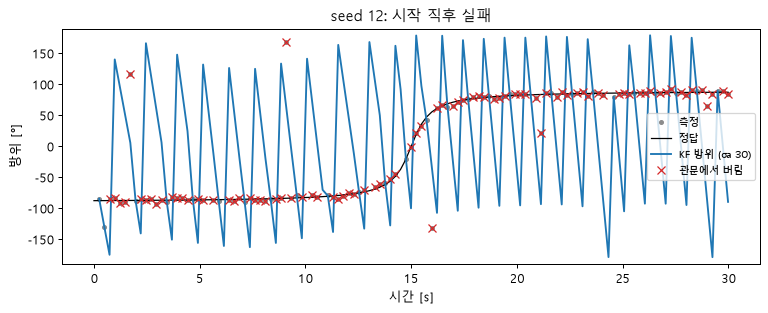

버림 87회, 놓침 0회, 갱신 26회


In [9]:
Zb = {n: sim.measure(tr, t, np.random.default_rng(10 + i), NOISE, gap=(12, 15) if n.startswith("D") else None)
      for i, (n, tr) in enumerate(S.items())}
nC = "C 직선 통과 (15 m/s, 10 m)"; trc = S[nC]
out = kf.track(t, Zb[nC], sigma_a=30)
print(" 주기 | 정답  | 측정 z | KF θ    KF ω   | 상태")
for k in range(8):
    o = out[k]
    print(f"{k:4d} | {trc[k]:5.1f} | {Zb[nC][k]:6.1f} | {o.get('theta', np.nan):7.1f} {o.get('omega', np.nan):7.1f} | {o['status']}")
th = np.array([o.get("theta", np.nan) for o in out]); st = [o["status"] for o in out]
plt.figure(figsize=(10, 3.4))
plt.plot(t, Zb[nC], ".", color="0.55", label="측정"); plt.plot(t, trc, "k", lw=1, label="정답"); plt.plot(t, th, color="C0", label="KF 방위 (σa 30)")
rj = np.array([s == "reject" for s in st]); plt.plot(t[rj], Zb[nC][rj], "x", color="C3", label="관문에서 버림")
plt.ylim(-190, 190); plt.xlabel("시간 [s]"); plt.ylabel("방위 [°]"); plt.legend(fontsize=8); plt.title("seed 12: 시작 직후 실패")
plt.show()
print(f"버림 {st.count('reject')}회, 놓침 {st.count('lost')}회, 갱신 {st.count('update')}회")

## 8. 결론 후보 (사용자 확인 전)

1. **차분 각속도로는 고정 음원 판정이 안 된다** — 2절: 흔들림 약 17°/s, 기준 ±3°/s.
2. **σa 하나로는 두 장면을 같이 만족하기 어렵다** — 6절 그림: 작은 σa는 A를 통과하지만 C에서 진짜 측정을 관문에서 버리고 놓친다. 큰 σa는 C를 따라가지만 A에서 ω가 흔들린다.
3. **선택지** (T2 미답 — 이 답을 받기 전에는 kf.py에 적용하지 않는다)
   - (가) 고정 판정은 KF ω 대신 **최근 몇 초의 누적 이동각**으로, KF는 σa = 30으로 추적만
   - (나) 모델 두 개(고정 / 움직임)를 같이 돌리는 IMM
   - (다) 상황에 따라 Q를 바꾸는 적응 Q

4. **추적 시작을 더 조심해야 한다** — 7절: 첫 두 측정으로 각속도를 크게 잡으면 엉뚱한 측정 하나에 추적이 망가진다. 후보: 시작 후 N개가 서로 맞을 때만 확정, 시작 직후 관문 제한, 틀린 추적을 끊는 규칙 (연속 버림 횟수).

**아직 모르는 것:** 대상이 먼 정찰기라면 각속도가 작다 (예: 200 m를 30 m/s로 지나가면 최근접에서 약 8.6°/s). 그 장면은 아직 넣지 않았다. 실제 doa 방위의 흔들림이 3°인지도 장면마다 다르다.